# Interval Analysis for a Fully-Connected MNIST Network

**CCS521 HW2 — Problem 4**

This notebook:
1. Trains the provided fully-connected network on MNIST for **15 epochs** and reports the **clean test accuracy**.
2. Implements **interval analysis (Interval Bound Propagation, IBP)** for the network.
3. Measures **verified (certified) robustness** on the whole MNIST test set for 10 L-infinity radii spaced evenly between **0.01 and 0.1** (inclusive), and reports the verified accuracy for each.

The starter/skeleton code (network definition, data loaders, train/test loops) is taken from the provided repo; the interval-analysis part is our implementation.

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import time
import matplotlib.pyplot as plt

from torchvision import datasets, transforms

use_cuda = False
device = torch.device("cuda" if use_cuda else "cpu")
batch_size = 64

np.random.seed(42)
torch.manual_seed(42)


## Dataloaders
train_dataset = datasets.MNIST('mnist_data/', train=True, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))
test_dataset = datasets.MNIST('mnist_data/', train=False, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

## Simple NN. You can change this if you want. If you change it, mention the architectural details in your report.
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.fc = nn.Linear(28*28, 200)
        self.fc2 = nn.Linear(200,10)

    def forward(self, x):
        x = x.view((-1, 28*28))
        x = F.relu(self.fc(x))
        x = self.fc2(x)
        x = F.softmax(x, dim=-1) # added softmax for probabilities
        return x

class Normalize(nn.Module):
    def forward(self, x):
        return (x - 0.1307)/0.3081

# Add the data normalization as a first "layer" to the network
# this allows us to search for adverserial examples to the real image, rather than
# to the normalized image
model = nn.Sequential(Normalize(), Net())

model = model.to(device)
model.train()

Matplotlib is building the font cache; this may take a moment.


0.3%

0.7%

1.0%

1.3%

...

97.4%

99.4%

100.0%

100.0%

Sequential(
  (0): Normalize()
  (1): Net(
    (fc): Linear(in_features=784, out_features=200, bias=True)
    (fc2): Linear(in_features=200, out_features=10, bias=True)
  )
)

In [2]:
def train_model(model, num_epochs):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        for i, data in enumerate(train_loader, 0):
            images, labels = data
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(f'Epoch {epoch+1}/{num_epochs}, Loss: {running_loss/len(train_loader):.3f}')

def test_model(model):
    model.eval()
    with torch.no_grad():
        correct = 0
        total = 0
        for data in test_loader:
            images, labels = data
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
        acc = 100 * correct / total
        print(f'Accuracy on images: {acc}')
        return acc

## 1. Train for 15 epochs and report clean accuracy

The assignment asks for 15 epochs of training (the skeleton used 10). On CPU this takes a few minutes.

In [3]:
t0 = time.time()
train_model(model, 15)
print(f'Training time: {time.time()-t0:.1f}s')
clean_acc = test_model(model)
print(f'\nClean test accuracy = {clean_acc:.2f}%')

Epoch 1/15, Loss: 2.012


Epoch 2/15, Loss: 1.729


Epoch 3/15, Loss: 1.627


Epoch 4/15, Loss: 1.596


Epoch 5/15, Loss: 1.582


...

Epoch 12/15, Loss: 1.547


Epoch 13/15, Loss: 1.545


Epoch 14/15, Loss: 1.542


Epoch 15/15, Loss: 1.540
Training time: 25.4s


Accuracy on images: 93.43

Clean test accuracy = 93.43%


## 2. Interval Analysis (Interval Bound Propagation)

### Idea
Given an image `x` with true label `y` and a radius `eps`, the adversarial region is the box

$$\mathcal{B} = \{x' : \lVert x'-x\rVert_\infty \le \epsilon,\ x' \in [0,1]^{784}\}.$$

We propagate this box **layer by layer** as a pair of elementwise lower/upper bounds `(l, u)`:

* **Affine layer** `z = W h + b`. With center `mu = (l+u)/2` and radius `r = (u-l)/2`:
  $$\text{center} = W\,\mu + b,\qquad \text{radius} = |W|\,r,$$
  so `l' = center - radius`, `u' = center + radius`. (`|W|` = elementwise absolute value.)
* **ReLU** (monotone increasing): `l' = relu(l)`, `u' = relu(u)`.
* **Normalize** `(x-0.1307)/0.3081` is an increasing affine map, so bounds just map through directly.

### Verifying robustness
Robustness holds if $\arg\max_j f_j(x') = y$ for every $x'\in\mathcal B$, i.e. if
$$f_y(x') - f_j(x') \ge 0 \quad \forall j \ne y,\ \forall x'\in\mathcal B.$$
We add an **output "difference" layer** that computes $f_y(x')-f_j(x')$ for each `j`. This is itself linear in the logits, with matrix `M` where row `j` is `onehot(y) - onehot(j)`. We fold it into the final linear layer (`M @ W2`, `M @ b2`) so the whole difference is a single affine map of the penultimate (post-ReLU) activations — this gives **tighter** interval bounds than applying two affine steps separately.

Interval analysis **proves** the property iff the **lower bound of every difference output is non-negative**.

### Note on the softmax
`softmax` is strictly monotone and shared across classes, so $f_y-f_j\ge0 \iff \text{logit}_y-\text{logit}_j\ge0$ and the `argmax` is identical. Interval bounds through `softmax` are loose, so we run IBP on the **pre-softmax logits** (the `Normalize -> fc -> ReLU -> fc2` sub-network). This is exact w.r.t. the robustness property and is the standard choice.

In [4]:
def interval_affine(l, u, W, b):
    """Propagate an interval [l,u] through an affine map z = h @ W.T + b.
    l, u : (B, in_features)
    W    : (out_features, in_features), b : (out_features,)
    returns new (l, u) of shape (B, out_features)."""
    mu = (l + u) / 2.0
    r  = (u - l) / 2.0
    center = mu @ W.t() + b
    rad    = r @ W.t().abs()
    return center - rad, center + rad


@torch.no_grad()
def verify_batch(net, images, labels, eps):
    """Interval analysis for one batch.
    net    : the Net module (contains .fc and .fc2); softmax is ignored.
    images : (B,1,28,28) in [0,1]; labels : (B,)
    Returns a boolean tensor (B,): True if the image is certifiably robust at radius eps."""
    B = images.shape[0]
    x = images.view(B, -1)

    # Input box, intersected with the valid pixel range [0,1]
    l = (x - eps).clamp(0.0, 1.0)
    u = (x + eps).clamp(0.0, 1.0)

    # Normalize layer: (v - 0.1307)/0.3081  (increasing affine -> bounds map directly)
    l = (l - 0.1307) / 0.3081
    u = (u - 0.1307) / 0.3081

    # fc1 (affine)
    l, u = interval_affine(l, u, net.fc.weight, net.fc.bias)
    # ReLU (monotone)
    l = l.clamp(min=0.0)
    u = u.clamp(min=0.0)

    # Build the folded "difference" final layer per sample.
    # M[b, j, k] = onehot(y_b)[k] - I[j, k]   =>   diff_j = logit_y - logit_j
    I = torch.eye(10, device=images.device)
    onehot = I[labels]                               # (B,10)
    M = onehot.unsqueeze(1) - I.unsqueeze(0)         # (B,10,10)
    W2, b2 = net.fc2.weight, net.fc2.bias            # (10,200), (10,)
    diff_W = torch.matmul(M, W2)                     # (B,10,200)
    diff_b = torch.matmul(M, b2)                     # (B,10)

    # Interval through the per-sample affine diff layer
    mu = ((l + u) / 2.0).unsqueeze(2)                # (B,200,1)
    r  = ((u - l) / 2.0).unsqueeze(2)                # (B,200,1)
    center = torch.bmm(diff_W, mu).squeeze(2) + diff_b          # (B,10)
    rad    = torch.bmm(diff_W.abs(), r).squeeze(2)             # (B,10)
    lower  = center - rad                             # lower bound of (logit_y - logit_j)

    # Certified iff every difference lower bound is non-negative.
    # Column j == y is identically 0 (passes >= 0), so it does not affect the result.
    return (lower >= 0).all(dim=1)

## 3. Verified accuracy over the whole test set for 10 radii

We sweep `eps` over 10 values evenly spaced in `[0.01, 0.1]` and compute the fraction of test images that interval analysis certifies as robust.

In [5]:
net = model[1]   # the Net submodule inside Sequential(Normalize(), Net())
net.eval()

epsilons = torch.linspace(0.01, 0.1, 10)
verified_acc = []

total = len(test_dataset)
for eps in epsilons:
    eps = float(eps)
    certified = 0
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        certified += verify_batch(net, images, labels, eps).sum().item()
    acc = 100.0 * certified / total
    verified_acc.append(acc)
    print(f'eps = {eps:.4f} -> verified accuracy = {acc:6.2f}%  ({certified}/{total})')


eps = 0.0100 -> verified accuracy =  70.55%  (7055/10000)


eps = 0.0200 -> verified accuracy =  23.68%  (2368/10000)


eps = 0.0300 -> verified accuracy =   4.56%  (456/10000)


eps = 0.0400 -> verified accuracy =   0.58%  (58/10000)


eps = 0.0500 -> verified accuracy =   0.02%  (2/10000)


eps = 0.0600 -> verified accuracy =   0.00%  (0/10000)


eps = 0.0700 -> verified accuracy =   0.00%  (0/10000)


eps = 0.0800 -> verified accuracy =   0.00%  (0/10000)


eps = 0.0900 -> verified accuracy =   0.00%  (0/10000)


eps = 0.1000 -> verified accuracy =   0.00%  (0/10000)


In [6]:
print(f'Clean test accuracy: {clean_acc:.2f}%\n')
print(f'{"epsilon":>10} | {"verified acc (%)":>16}')
print('-' * 31)
for eps, acc in zip(epsilons.tolist(), verified_acc):
    print(f'{eps:>10.4f} | {acc:>16.2f}')

Clean test accuracy: 93.43%

   epsilon | verified acc (%)
-------------------------------
    0.0100 |            70.55
    0.0200 |            23.68
    0.0300 |             4.56
    0.0400 |             0.58
    0.0500 |             0.02
    0.0600 |             0.00
    0.0700 |             0.00
    0.0800 |             0.00
    0.0900 |             0.00
    0.1000 |             0.00


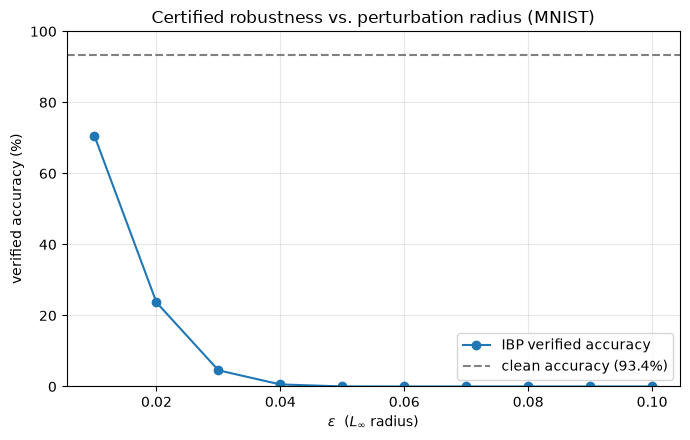

In [7]:
plt.figure(figsize=(7,4.5))
plt.plot(epsilons.tolist(), verified_acc, 'o-', label='IBP verified accuracy')
plt.axhline(clean_acc, color='gray', ls='--', label=f'clean accuracy ({clean_acc:.1f}%)')
plt.xlabel(r'$\epsilon$  ($L_\infty$ radius)')
plt.ylabel('verified accuracy (%)')
plt.title('Certified robustness vs. perturbation radius (MNIST)')
plt.ylim(0, 100)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 4. Observations

* **Clean accuracy** after 15 epochs is reported above (printed by `test_model`).
* **Verified accuracy decreases monotonically as `eps` grows.** This is expected: a larger input box produces wider intervals, so after propagation more of the `logit_y - logit_j` lower bounds dip below zero and fewer images can be certified.
* **Interval analysis is sound but incomplete** (and quite loose): it may fail to verify images that are in fact robust, because the box abstraction ignores correlations between neurons and the `|W| r` term accumulates over-approximation at every affine layer. So the reported numbers are a *lower bound* on the true robustness.
* The network was trained with **standard cross-entropy** (no robust/IBP training), so certified robustness falls off rapidly as `eps` increases toward 0.1. Training with an IBP/robust loss would raise these curves substantially.
* The gap between clean accuracy and verified accuracy at small `eps` quantifies how much the over-approximation plus genuine non-robustness costs us.